# Лабораторная работа № 3 · вариант 6
## Классификация изображений отходов — Kaggle Garbage Classification

Кононенко С. В., группа 4332. Адаптация [исходной ЛР3](https://github.com/imnoname/intelligent-data-analysis-ml/blob/7e6e317b572f07a853dc55797137338c3160d83f/lr3/lr3_variant6_flower_image_classification.ipynb). Вместо TensorFlow Flowers используем [Kaggle Garbage Classification](https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification). По фотографии определяем один из шести классов: cardboard, glass, metal, paper, plastic, trash.

Сохранены основные модели и дополнительные опыты: своя CNN, MobileNetV2 с ImageNet-весами, автоэнкодер и Dense; затем CNN без явной регуляризации, fine-tuning MobileNetV2 и компактный автоэнкодер.

Запускайте ячейки сверху вниз. Для запуска из корня репозитория нужен Python 3.12 с пакетами из `lr3/requirements.txt`. Архив фотографий и веса MobileNetV2 лежат в `lr3/data`. Снимки побайтно совпадают с фотографиями из Kaggle. Разбиение создаётся с seed 42. [Инструкция по повторному обучению](lr3/README.md).

> **Результат исходного прогона (`EPOCH_MULTIPLIER = 1`):** На **test** из 379 фото лучший macro-F1 среди основных моделей у **MobileNetV2 frozen**: **0.771**, accuracy **80.7%**. На **validation** среди всех конфигураций лидирует **MobileNetV2 frozen**: macro-F1 **0.778**.

## 1. Среда и параметры обучения

`EPOCH_MULTIPLIER` увеличивает максимальное число эпох и время ожидания `EarlyStopping` во всех опытах. Сохранённые результаты получены со значением `1`. Для более длинного прогона поставьте, например, `3`. Обучение может остановиться раньше лимита, если ошибка на validation перестанет уменьшаться.


In [1]:
import os, random, sys
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "6")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from hashlib import sha256, file_digest
from io import BytesIO
from PIL import Image, ImageOps
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
 precision_recall_fscore_support, confusion_matrix, log_loss, classification_report)
from IPython.display import display, Markdown
SEED=42; random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
IMG_SIZE=(96,96); BATCH_SIZE=32; AUTOTUNE=tf.data.AUTOTUNE
EPOCH_MULTIPLIER = int(os.environ.get("LR3_EPOCH_MULTIPLIER", "1"))
if EPOCH_MULTIPLIER < 1:
    raise ValueError("EPOCH_MULTIPLIER должен быть положительным целым числом.")
sns.set_theme(style="whitegrid", palette=["#246759", "#b95a31"])
print("Python:", sys.version.split()[0], "| TensorFlow:", tf.__version__)
print("Устройства:", [d.device_type for d in tf.config.list_physical_devices()])
print("Размер изображения:",IMG_SIZE,"batch:",BATCH_SIZE,"seed:",SEED)

Python: 3.12.14 | TensorFlow: 2.21.0
Устройства: ['CPU']
Размер изображения: (96, 96) batch: 32 seed: 42


In [2]:
DATASET_URL = "https://www.kaggle.com/api/v1/datasets/download/asdasdasasdas/garbage-classification"
ARCHIVE_SHA256 = "9d76dce1c47d23c92adc3d461d3ea6191070220e6238f9aa60c2ee61227ad88b"
KAGGLE_ROOT = "Garbage classification/Garbage classification"
BUNDLED_ARCHIVE = Path("lr3/data/trashnet.zip")
TRASHNET_SHA256 = "0bf472790f8b20e5c950d5b5012a9d38af0d3392efd65f8ce171334fc16b07c2"
ARCHIVE_ROOTS = {ARCHIVE_SHA256: KAGGLE_ROOT, TRASHNET_SHA256: "dataset-resized"}
class_names = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
NUM_CLASSES = len(class_names)
CLASS_TO_ID = {name: i for i, name in enumerate(class_names)}

def load_archive():
    local = os.environ.get("LR3_KAGGLE_ARCHIVE")
    if local or BUNDLED_ARCHIVE.is_file():
        archive = Path(local).expanduser() if local else BUNDLED_ARCHIVE
        with archive.open("rb") as stream:
            digest = file_digest(stream, "sha256").hexdigest()
        if digest not in ARCHIVE_ROOTS:
            raise ValueError("ZIP не совпадает с проверенным архивом TrashNet или Kaggle.")
        return archive, ARCHIVE_ROOTS[digest]
    archive = tf.keras.utils.get_file(
        "lr3-kaggle-garbage-9d76dce1.zip", origin=DATASET_URL,
        file_hash=ARCHIVE_SHA256, hash_algorithm="sha256", cache_subdir="datasets",
    )
    return Path(archive), KAGGLE_ROOT

def read_dataset(archive, archive_root):
    rows, images, broken = [], [], []
    with ZipFile(archive) as zf:
        members = sorted(n for n in zf.namelist()
                         if n.startswith(archive_root + "/")
                         and PurePosixPath(n).parent.name in CLASS_TO_ID
                         and PurePosixPath(n).suffix.lower() in {".jpg", ".jpeg", ".png"})
        for name in members:
            data = zf.read(name)
            cls = PurePosixPath(name).parent.name
            try:
                with Image.open(BytesIO(data)) as raw:
                    rgb = ImageOps.exif_transpose(raw).convert("RGB")
                    width, height = rgb.size
                    resized = rgb.resize((IMG_SIZE[1], IMG_SIZE[0]), Image.Resampling.BILINEAR)
                    pixels = np.asarray(resized, dtype=np.uint8)
            except (OSError, ValueError):
                broken.append(name)
                continue
            rows.append({"member": name, "class": cls, "label": CLASS_TO_ID[cls],
                         "digest": sha256(data).hexdigest(), "width": width, "height": height,
                         "image_id": len(images)})
            images.append(pixels)
    if not images:
        raise ValueError("В архиве нет изображений ожидаемой структуры.")
    valid = pd.DataFrame(rows)
    groups = valid.groupby("digest")["label"].nunique()
    ambiguous = groups[groups > 1].index
    unambiguous = valid.loc[~valid.digest.isin(ambiguous)]
    clean = unambiguous.drop_duplicates("digest").reset_index(drop=True)
    summary = {
        "файлов в одном дереве архива": len(members),
        "повреждённых файлов": len(broken),
        "копий с одинаковой меткой удалено": len(unambiguous) - len(clean),
        "файлов с противоречивой меткой удалено": len(valid) - len(unambiguous),
        "изображений после очистки": len(clean),
    }
    return clean, np.stack(images), summary

## 2. Загрузка и разведочный анализ

В репозитории лежит архив авторов TrashNet с 2 527 снимками. Архив Kaggle содержит два одинаковых дерева с разным регистром папок, поэтому при загрузке с Kaggle читается только одно. Метка определяется папкой. Перед разбиением исключаем повреждённые файлы и точные дубли по SHA-256. Хеш байтов не выявляет похожие или пересохранённые снимки.


,Количество
файлов в одном дереве архива,2527
повреждённых файлов,0
копий с одинаковой меткой удалено,0
файлов с противоречивой меткой удалено,6
изображений после очистки,2521


,Фотографий после очистки
class,
cardboard,403
glass,498
metal,409
paper,594
plastic,480
trash,137


,,Файлов
width,height,
512,384,2521


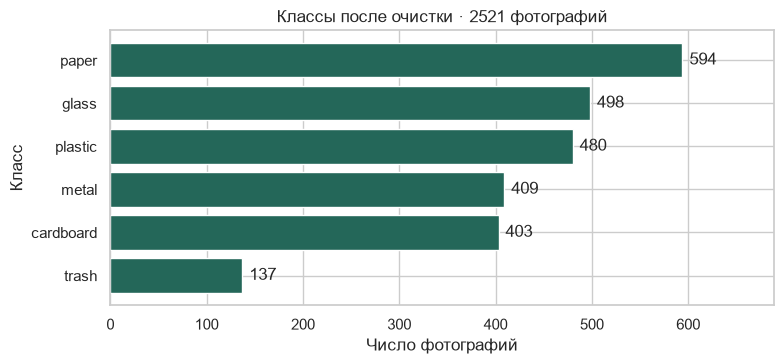

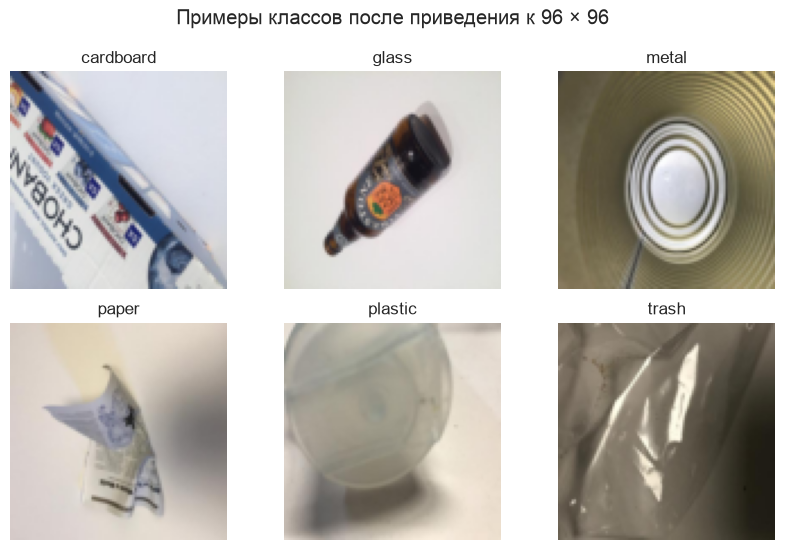

In [3]:
df, images, audit = read_dataset(*load_archive())
assert audit["файлов в одном дереве архива"] == 2527
assert set(df["class"]) == set(class_names)
assert df.digest.is_unique and df.member.is_unique
assert images.shape[1:] == (*IMG_SIZE, 3)
display(pd.Series(audit, name="Количество").to_frame())
counts = df["class"].value_counts().reindex(class_names)
display(counts.rename("Фотографий после очистки").to_frame())
display(df.groupby(["width", "height"]).size().nlargest(8).rename("Файлов").to_frame())

fig, ax = plt.subplots(figsize=(8, 3.8))
ordered = counts.sort_values()
bars = ax.barh(ordered.index, ordered.values, color="#246759")
ax.bar_label(bars, padding=5)
ax.set_xlim(0, max(counts) * 1.16)
ax.set_title(f"Классы после очистки · {len(df)} фотографий")
ax.set_xlabel("Число фотографий")
ax.set_ylabel("Класс")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(8.4, 5.6))
for name, ax in zip(class_names, axes.flat):
    row = df.loc[df["class"].eq(name)].sample(1, random_state=SEED).iloc[0]
    ax.imshow(images[row.image_id])
    ax.set_title(name)
    ax.axis("off")
fig.suptitle("Примеры классов после приведения к 96 × 96")
fig.tight_layout()
plt.show()

## 3. Разбиение и подготовка изображений

Стратифицированное разбиение примерно 70/15/15 сохраняет доли классов. Проверяем отсутствие общих файлов и хешей. Изображения декодированы в RGB и приведены к 96 × 96. TensorFlow выдаёт батчи, перемешивая только train. Автоэнкодер получает изображение в диапазоне 0–1 как вход и цель. Классификаторы масштабируют пиксели внутри модели.

In [4]:
train_df, test_df = train_test_split(df, test_size=.15, random_state=SEED, stratify=df.label)
train_df, val_df = train_test_split(train_df, test_size=.15/.85, random_state=SEED, stratify=train_df.label)
train_df, val_df, test_df = (part.reset_index(drop=True) for part in (train_df, val_df, test_df))
parts = {"train": train_df, "validation": val_df, "test": test_df}
for key in ("member", "digest", "image_id"):
    a, b, c = (set(part[key]) for part in parts.values())
    assert not (a & b or a & c or b & c), key
assert sum(map(len, parts.values())) == len(df)
for part in parts.values():
    assert set(part.label) == set(range(NUM_CLASSES))
print("Размеры выборок:", {name: len(part) for name, part in parts.items()})
display(pd.DataFrame({name: part["class"].value_counts().reindex(class_names) for name, part in parts.items()}))

def make_ds(part, training=False, ae=False):
    x = images[part.image_id.to_numpy()]
    y = part.label.to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(part), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if ae:
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255., tf.cast(x, tf.float32) / 255.),
                    num_parallel_calls=2)
    else:
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=2)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 4
    return ds.with_options(options).prefetch(2)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)
ae_train_ds = make_ds(train_df, training=True, ae=True)
ae_val_ds = make_ds(val_df, ae=True)
x, y = next(iter(train_ds))
assert x.shape[1:] == (*IMG_SIZE, 3)
print("Размер батча:", x.shape, "| диапазон:", float(tf.reduce_min(x)), "–", float(tf.reduce_max(x)))

Размеры выборок: {'train': 1764, 'validation': 378, 'test': 379}


,train,validation,test
class,,,
cardboard,282,60,61
glass,348,75,75
metal,287,61,61
paper,416,89,89
plastic,336,72,72
trash,95,21,21


Размер батча: (32, 96, 96, 3) | диапазон: 0.0 – 255.0


## 4. Метрики

- **Accuracy** — доля верных ответов. **Balanced accuracy** — средняя полнота по классам.
- **Precision** — доля правильных ответов среди фото, названных этим классом. **Recall** — доля найденных фото среди всех настоящих фото класса.
- **F1** учитывает precision и recall. **Macro-F1** усредняет F1 с одинаковым весом каждого класса.
- **Cross-entropy** штрафует уверенные ошибки классификации. **MSE** измеряет ошибку восстановления пикселей. Это разные задачи, их потери не сравниваем как одну метрику.
- Матрица ошибок: строки — истинные классы, столбцы — предсказанные, диагональ — верные ответы.

Эпоху выбираем по validation loss, конфигурации сравниваем по validation macro-F1. Test не участвует в выборе.

In [5]:
Y_VAL = val_df.label.to_numpy()
def score(y,probs):
    assert probs.shape == (len(y), NUM_CLASSES)
    assert np.isfinite(probs).all() and np.allclose(probs.sum(axis=1), 1, atol=1e-5)
    pred=probs.argmax(axis=1); p,r,f,_=precision_recall_fscore_support(y,pred,labels=np.arange(len(class_names)),zero_division=0)
    return {"accuracy":accuracy_score(y,pred),"balanced_accuracy":balanced_accuracy_score(y,pred),"macro_precision":p.mean(),"macro_recall":r.mean(),"macro_f1":f.mean(),"cross_entropy":log_loss(y,probs,labels=np.arange(len(class_names))),**{f"F1: {class_names[i]}":f[i] for i in range(len(f))}}
def curves(h,title):
    fig,ax=plt.subplots(1,2,figsize=(11,4))
    for k in ("loss","val_loss"):
        if k in h.history: ax[0].plot(range(1,len(h.history[k])+1),h.history[k],label=k,linestyle="--" if k.startswith("val_") else "-")
    for k in ("accuracy","val_accuracy"):
        if k in h.history: ax[1].plot(range(1,len(h.history[k])+1),h.history[k],label=k,linestyle="--" if k.startswith("val_") else "-")
    ax[0].set_title("Loss"); ax[1].set_title("Accuracy")
    for a in ax:
        a.set_xlabel("Эпоха"); a.grid(alpha=.25)
        if a.lines: a.legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()
results={}; val_probs={}; test_probs={}

## 5. Основная модель A — собственная CNN

Свёрточные слои извлекают локальные признаки формы и текстуры. После pooling и двух Dense-слоёв softmax выдаёт шесть вероятностей. Отражение и небольшой поворот применяются только на train. Dropout и L2 ограничивают переобучение; EarlyStopping выбирает веса по validation loss.

Модель A: Conv2D 32→64→128 → GAP → Dense128 → Dropout(.35) → Dense64 → Softmax(6); L2=1e-4; augmentation=flip/rotation


Model: "custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,406 (462.52 KB)

 Trainable params: 118,406 (462.52 KB)

 Non-trainable params: 0 (0.00 B)

... (16 outputs left out)

Epoch 9/10


56/56 - 3s - 55ms/step - accuracy: 0.4121 - loss: 1.4076 - val_accuracy: 0.4233 - val_loss: 1.4166


Epoch 10/10


56/56 - 3s - 52ms/step - accuracy: 0.4450 - loss: 1.3628 - val_accuracy: 0.4418 - val_loss: 1.3747


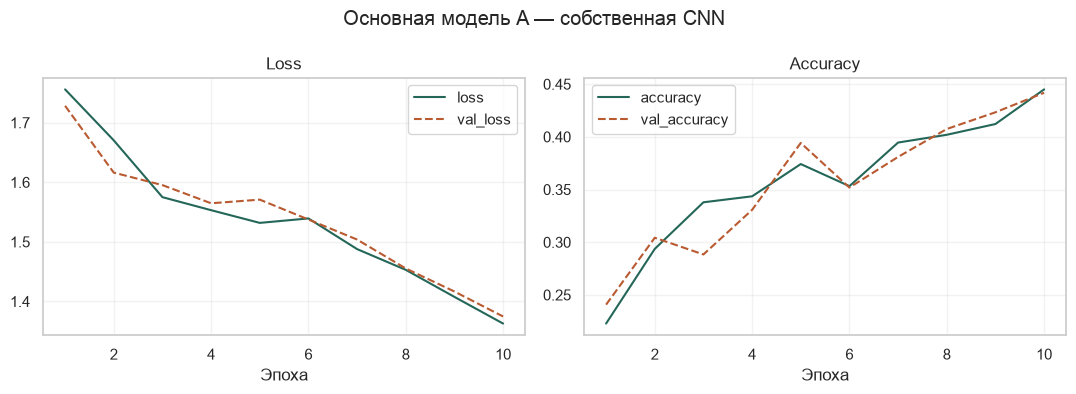

In [6]:
def augment(): return tf.keras.Sequential([tf.keras.layers.RandomFlip("horizontal"),tf.keras.layers.RandomRotation(.08)])
def build_cnn(width=32,drop=.35,l2=1e-4,use_aug=True):
    reg=tf.keras.regularizers.l2(l2) if l2 else None; inp=tf.keras.Input((*IMG_SIZE,3)); x=inp
    if use_aug: x=augment()(x)
    x=tf.keras.layers.Rescaling(1/255.)(x)
    for f in (width,width*2,width*4): x=tf.keras.layers.MaxPooling2D()(tf.keras.layers.Conv2D(f,3,padding="same",activation="relu",kernel_regularizer=reg)(x))
    x=tf.keras.layers.GlobalAveragePooling2D()(x); x=tf.keras.layers.Dense(128,activation="relu",kernel_regularizer=reg)(x); x=tf.keras.layers.Dropout(drop)(x)
    x=tf.keras.layers.Dense(64,activation="relu",kernel_regularizer=reg)(x); out=tf.keras.layers.Dense(NUM_CLASSES,activation="softmax")(x)
    m=tf.keras.Model(inp,out,name="custom_CNN"); m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m
cnn=build_cnn(); print("Модель A: Conv2D 32→64→128 → GAP → Dense128 → Dropout(.35) → Dense64 → Softmax(6); L2=1e-4; augmentation=flip/rotation"); cnn.summary()
h_cnn=cnn.fit(train_ds,validation_data=val_ds,epochs=10 * EPOCH_MULTIPLIER,shuffle=False,callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=2 * EPOCH_MULTIPLIER,restore_best_weights=True)],verbose=2)
curves(h_cnn,"Основная модель A — собственная CNN")
val_probs["CNN"]=cnn.predict(val_ds,verbose=0); results["CNN"]=score(Y_VAL,val_probs["CNN"])

## 6. Основная модель B — MobileNetV2 transfer learning
MobileNetV2 с ImageNet-весами используется как готовый извлекатель визуальных признаков. Свёрточная основа заморожена, обучается регуляризованная Dense-голова на шесть классов отходов. `preprocess_input` приводит пиксели к диапазону `[-1,1]`, ожидаемому сетью. Аугментация действует только на тренировочные примеры. На графиках оцениваем скорость обучения и переобучение.

      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  49152/9406464 ━━━━━━━━━━━━━━━━━━━━ 20s 2us/step

  81920/9406464 ━━━━━━━━━━━━━━━━━━━━ 23s 3us/step

 114688/9406464 ━━━━━━━━━━━━━━━━━━━━ 24s 3us/step

 540672/9406464 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step 

 745472/9406464 ━━━━━━━━━━━━━━━━━━━━ 4s 1us/step

... (42 outputs left out)

Epoch 6/7


56/56 - 1s - 25ms/step - accuracy: 0.8486 - loss: 0.4334 - val_accuracy: 0.7884 - val_loss: 0.6669


Epoch 7/7


56/56 - 1s - 25ms/step - accuracy: 0.8685 - loss: 0.3730 - val_accuracy: 0.7857 - val_loss: 0.6522


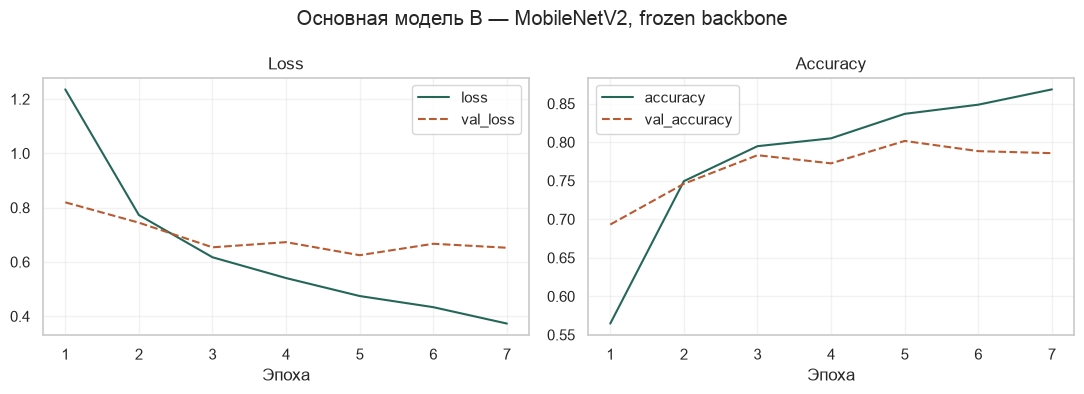

In [7]:
MOBILENET_WEIGHTS = Path("lr3/data/mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_96_no_top.h5")

def build_mobile():
    weights = str(MOBILENET_WEIGHTS) if MOBILENET_WEIGHTS.is_file() else "imagenet"
    base=tf.keras.applications.MobileNetV2(include_top=False,weights=weights,input_shape=(*IMG_SIZE,3)); base.trainable=False
    inp=tf.keras.Input((*IMG_SIZE,3)); x=augment()(inp); x=tf.keras.applications.mobilenet_v2.preprocess_input(x); x=base(x,training=False)
    x=tf.keras.layers.GlobalAveragePooling2D()(x); x=tf.keras.layers.Dense(128,activation="relu",kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x); x=tf.keras.layers.Dropout(.35)(x)
    out=tf.keras.layers.Dense(NUM_CLASSES,activation="softmax")(x); m=tf.keras.Model(inp,out,name="MobileNetV2_transfer")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m,base
mobile,mobile_base=build_mobile(); print("Модель B: frozen MobileNetV2 ImageNet → GAP → Dense128(L2) → Dropout(.35) → Softmax(6); обучается только голова"); print("Обучаемых параметров:",sum(np.prod(v.shape) for v in mobile.trainable_weights)); mobile.summary()
h_mobile=mobile.fit(train_ds,validation_data=val_ds,epochs=7 * EPOCH_MULTIPLIER,shuffle=False,callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=2 * EPOCH_MULTIPLIER,restore_best_weights=True)],verbose=2)
curves(h_mobile,"Основная модель B — MobileNetV2, frozen backbone")
val_probs["MobileNetV2 frozen"]=mobile.predict(val_ds,verbose=0); results["MobileNetV2 frozen"]=score(Y_VAL,val_probs["MobileNetV2 frozen"])

## 7. Основная модель C — свёрточный автоэнкодер и Dense

Автоэнкодер учится без меток восстанавливать вход. MSE измеряет расхождение пикселей. Энкодер замораживается, затем Dense учится на его признаках и метках train. Test подаём в энкодер только на финальной проверке.

Модель C1: encoder Conv2D stride2 32→64→128→latent64; decoder Conv2DTranspose → 96×96×3; loss=MSE; без меток, только train


Model: "autoencoder64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder64 (Functional)          │ (None, 12, 12, 64)     │       101,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_2 (Functional)       │ (None, 96, 96, 3)      │       166,979 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 268,483 (1.02 MB)

 Trainable params: 268,483 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

Epoch 5/6


56/56 - 5s - 86ms/step - loss: 0.0043 - val_loss: 0.0047


Epoch 6/6


56/56 - 5s - 87ms/step - loss: 0.0036 - val_loss: 0.0031


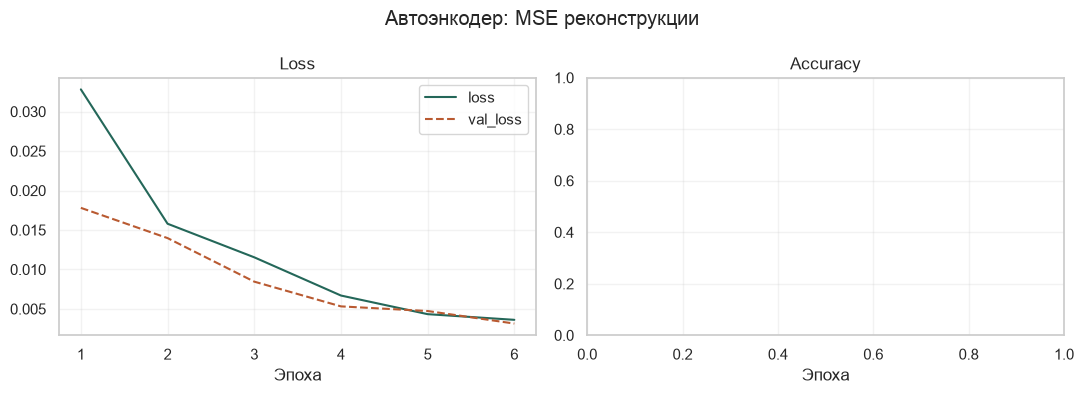

Модель C2: frozen embeddings (9216 признаков) → Dense128 → Dropout → Dense64 → Softmax(6)


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,188,422 (4.53 MB)

 Trainable params: 1,188,422 (4.53 MB)

 Non-trainable params: 0 (0.00 B)

... (12 outputs left out)

Epoch 7/18


56/56 - 0s - 2ms/step - accuracy: 0.4762 - loss: 1.3317 - val_accuracy: 0.4550 - val_loss: 1.3692


Epoch 8/18


56/56 - 0s - 2ms/step - accuracy: 0.4864 - loss: 1.3179 - val_accuracy: 0.4868 - val_loss: 1.3427


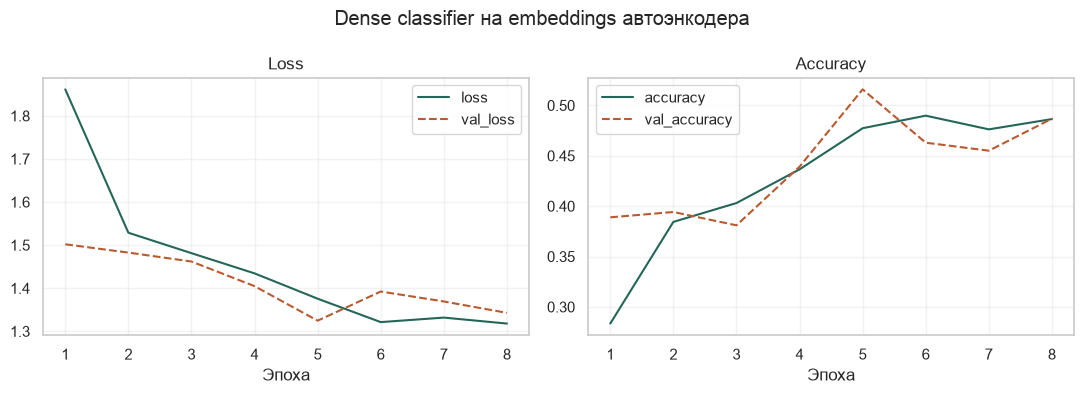

In [8]:
def build_ae(latent=64):
    inp=tf.keras.Input((*IMG_SIZE,3)); x=inp
    for f in (32,64,128): x=tf.keras.layers.Conv2D(f,3,strides=2,padding="same",activation="relu")(x)
    z=tf.keras.layers.Conv2D(latent,1,activation="relu",name="latent")(x); enc=tf.keras.Model(inp,z,name=f"encoder{latent}")
    zi=tf.keras.Input(tuple(z.shape[1:])); x=zi
    for f in (128,64,32): x=tf.keras.layers.Conv2DTranspose(f,3,strides=2,padding="same",activation="relu")(x)
    out=tf.keras.layers.Conv2D(3,3,padding="same",activation="sigmoid")(x); dec=tf.keras.Model(zi,out)
    ae=tf.keras.Model(inp,dec(enc(inp)),name=f"autoencoder{latent}"); ae.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="mse"); return enc,ae
def embed(enc,part):
    out=[]
    for x,_ in make_ds(part): out.append(enc(x/255.,training=False).numpy().reshape((x.shape[0],-1)))
    return np.concatenate(out)
def build_head(dim):
    inp=tf.keras.Input((dim,)); x=tf.keras.layers.Dense(128,activation="relu",kernel_regularizer=tf.keras.regularizers.l2(1e-4))(inp); x=tf.keras.layers.Dropout(.35)(x)
    x=tf.keras.layers.Dense(64,activation="relu")(x); out=tf.keras.layers.Dense(NUM_CLASSES,activation="softmax")(x); m=tf.keras.Model(inp,out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m
encoder,ae=build_ae(64); print("Модель C1: encoder Conv2D stride2 32→64→128→latent64; decoder Conv2DTranspose → 96×96×3; loss=MSE; без меток, только train"); ae.summary()
h_ae=ae.fit(ae_train_ds,validation_data=ae_val_ds,epochs=6 * EPOCH_MULTIPLIER,shuffle=False,callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=2 * EPOCH_MULTIPLIER,restore_best_weights=True)],verbose=2); curves(h_ae,"Автоэнкодер: MSE реконструкции")
encoder.trainable=False; Xtr=embed(encoder,train_df); Xva=embed(encoder,val_df); ytr=train_df.label.to_numpy(); yva=val_df.label.to_numpy()
head=build_head(Xtr.shape[1]); print(f"Модель C2: frozen embeddings ({Xtr.shape[1]} признаков) → Dense128 → Dropout → Dense64 → Softmax(6)"); head.summary()
h_head=head.fit(Xtr,ytr,validation_data=(Xva,yva),epochs=18 * EPOCH_MULTIPLIER,batch_size=BATCH_SIZE,callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=3 * EPOCH_MULTIPLIER,restore_best_weights=True)],verbose=2)
curves(h_head,"Dense classifier на embeddings автоэнкодера"); val_probs["Autoencoder + Dense"]=head.predict(Xva,verbose=0); results["Autoencoder + Dense"]=score(Y_VAL,val_probs["Autoencoder + Dense"])

## 8. Опыт E1 — более узкая CNN без аугментации и регуляризации

Сравниваем с основной CNN. Одновременно меняются аугментация, Dropout, L2, ширина и лимит эпох, поэтому нельзя приписать разницу одному фактору.

Опыт E1: Conv2D 24→48→96 → GAP → Dense128 → Dense64 → Softmax; augmentation OFF, dropout OFF, L2 OFF; максимум 5 эпох
Epoch 1/5


56/56 - 3s - 49ms/step - accuracy: 0.2273 - loss: 1.7310 - val_accuracy: 0.2381 - val_loss: 1.7289


Epoch 2/5


56/56 - 2s - 35ms/step - accuracy: 0.2687 - loss: 1.6887 - val_accuracy: 0.3598 - val_loss: 1.5962


Epoch 3/5


56/56 - 2s - 35ms/step - accuracy: 0.3668 - loss: 1.5418 - val_accuracy: 0.3492 - val_loss: 1.5309


Epoch 4/5


56/56 - 2s - 35ms/step - accuracy: 0.4144 - loss: 1.4238 - val_accuracy: 0.4021 - val_loss: 1.5372


Epoch 5/5


56/56 - 2s - 39ms/step - accuracy: 0.4110 - loss: 1.4220 - val_accuracy: 0.3677 - val_loss: 1.5534


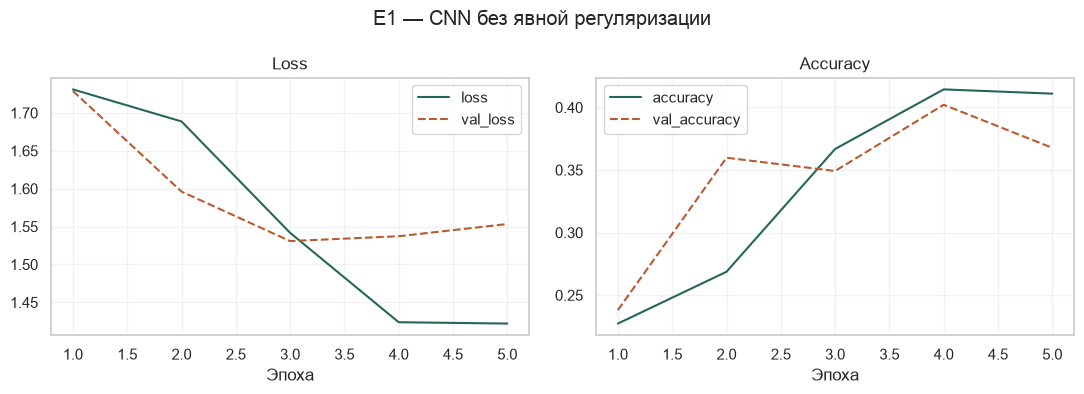

In [9]:
cnn_plain=build_cnn(width=24,drop=0,l2=0,use_aug=False)
print(f"Опыт E1: Conv2D 24→48→96 → GAP → Dense128 → Dense64 → Softmax; augmentation OFF, dropout OFF, L2 OFF; максимум {5 * EPOCH_MULTIPLIER} эпох")
h_plain=cnn_plain.fit(train_ds,validation_data=val_ds,epochs=5 * EPOCH_MULTIPLIER,shuffle=False,callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=2 * EPOCH_MULTIPLIER,restore_best_weights=True)],verbose=2)
curves(h_plain,"E1 — CNN без явной регуляризации"); val_probs["CNN no regularization"]=cnn_plain.predict(val_ds,verbose=0); results["CNN no regularization"]=score(Y_VAL,val_probs["CNN no regularization"])

## 9. Расширенный эксперимент 2 — частичный fine-tuning MobileNetV2
Копируем исходно обученную MobileNetV2, размораживаем только последние 20 слоёв и используем малый learning rate `1e-5`. BatchNormalization остаётся замороженной, ранние слои не изменяются. Это проверяет, улучшает ли ограниченная адаптация ImageNet-фильтров качество на фотографиях отходов. Сравниваем validation macro-F1 и кривые.

Опыт E2: MobileNetV2 последние 20 слоёв trainable, BatchNorm frozen; Dense head; Adam=1e-5; максимум 4 эпохи; trainable params: 1359622
Epoch 1/4


56/56 - 5s - 84ms/step - accuracy: 0.8690 - loss: 0.4015 - val_accuracy: 0.7937 - val_loss: 0.6193


Epoch 2/4


56/56 - 2s - 31ms/step - accuracy: 0.8849 - loss: 0.3543 - val_accuracy: 0.7963 - val_loss: 0.6262


Epoch 3/4


56/56 - 2s - 31ms/step - accuracy: 0.8946 - loss: 0.3197 - val_accuracy: 0.8148 - val_loss: 0.6380


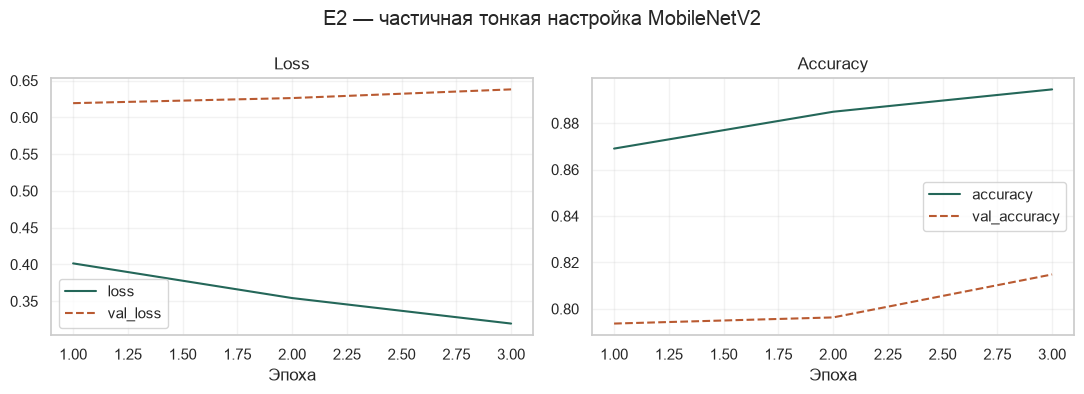

In [10]:
mobile_ft,base_ft=build_mobile(); mobile_ft.set_weights(mobile.get_weights()); base_ft.trainable=True
for layer in base_ft.layers[:-20]: layer.trainable=False
for layer in base_ft.layers:
    if isinstance(layer,tf.keras.layers.BatchNormalization): layer.trainable=False
mobile_ft.compile(optimizer=tf.keras.optimizers.Adam(1e-5),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
print(f"Опыт E2: MobileNetV2 последние 20 слоёв trainable, BatchNorm frozen; Dense head; Adam=1e-5; максимум {4 * EPOCH_MULTIPLIER} эпох; trainable params:",sum(np.prod(v.shape) for v in mobile_ft.trainable_weights))
h_ft=mobile_ft.fit(train_ds,validation_data=val_ds,epochs=4 * EPOCH_MULTIPLIER,shuffle=False,callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=2 * EPOCH_MULTIPLIER,restore_best_weights=True)],verbose=2)
curves(h_ft,"E2 — частичная тонкая настройка MobileNetV2"); val_probs["MobileNetV2 fine-tuned"]=mobile_ft.predict(val_ds,verbose=0); results["MobileNetV2 fine-tuned"]=score(Y_VAL,val_probs["MobileNetV2 fine-tuned"])

## 10. Опыт E3 — компактное скрытое описание

Меняем 64 скрытых канала на 32 и сокращаем лимиты обучения. Затем учим Dense на замороженных признаках. Сравниваем реконструкцию и классификацию отдельно. Это сравнение двух конфигураций, а не изолированный тест размерности.

Опыт E3a: Conv AE latent=32, только train без меток; reconstruction MSE; максимум 4 эпохи


Model: "autoencoder32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder32 (Functional)          │ (None, 12, 12, 32)     │        97,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_5 (Functional)       │ (None, 96, 96, 3)      │       130,115 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 227,491 (888.64 KB)

 Trainable params: 227,491 (888.64 KB)

 Non-trainable params: 0 (0.00 B)

... (4 outputs left out)

Epoch 3/4


56/56 - 4s - 79ms/step - loss: 0.0143 - val_loss: 0.0140


Epoch 4/4


56/56 - 4s - 79ms/step - loss: 0.0118 - val_loss: 0.0059


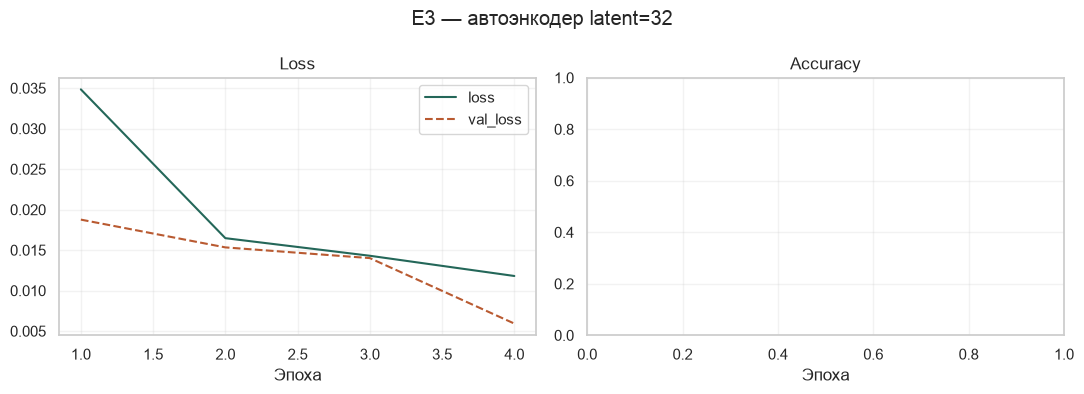

Опыт E3b: Dense128 → Dropout → Dense64 → Softmax, 4608 признаков; encoder frozen
Epoch 1/10


56/56 - 1s - 10ms/step - accuracy: 0.3430 - loss: 1.6590 - val_accuracy: 0.4365 - val_loss: 1.4963


Epoch 2/10


56/56 - 0s - 1ms/step - accuracy: 0.4331 - loss: 1.4413 - val_accuracy: 0.4577 - val_loss: 1.4214


Epoch 3/10


56/56 - 0s - 1ms/step - accuracy: 0.4864 - loss: 1.3830 - val_accuracy: 0.4365 - val_loss: 1.3655


... (10 outputs left out)

Epoch 9/10


56/56 - 0s - 1ms/step - accuracy: 0.5533 - loss: 1.1925 - val_accuracy: 0.4868 - val_loss: 1.2750


Epoch 10/10


56/56 - 0s - 1ms/step - accuracy: 0.5686 - loss: 1.1329 - val_accuracy: 0.4947 - val_loss: 1.3073


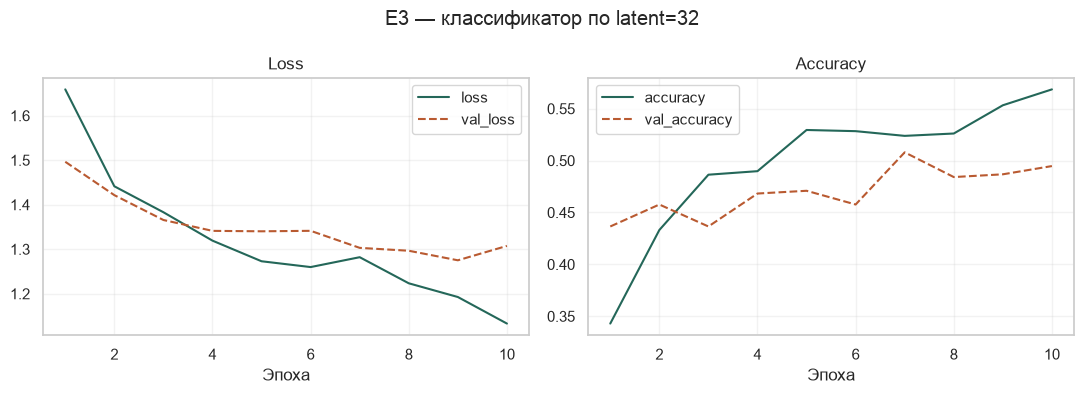

In [11]:
enc32,ae32=build_ae(32); print(f"Опыт E3a: Conv AE latent=32, только train без меток; reconstruction MSE; максимум {4 * EPOCH_MULTIPLIER} эпох"); ae32.summary()
h_ae32=ae32.fit(ae_train_ds,validation_data=ae_val_ds,epochs=4 * EPOCH_MULTIPLIER,shuffle=False,callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=2 * EPOCH_MULTIPLIER,restore_best_weights=True)],verbose=2); curves(h_ae32,"E3 — автоэнкодер latent=32")
enc32.trainable=False; Xtr32=embed(enc32,train_df); Xva32=embed(enc32,val_df); head32=build_head(Xtr32.shape[1])
print(f"Опыт E3b: Dense128 → Dropout → Dense64 → Softmax, {Xtr32.shape[1]} признаков; encoder frozen")
h_head32=head32.fit(Xtr32,ytr,validation_data=(Xva32,yva),epochs=10 * EPOCH_MULTIPLIER,batch_size=BATCH_SIZE,callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=2 * EPOCH_MULTIPLIER,restore_best_weights=True)],verbose=2)
curves(h_head32,"E3 — классификатор по latent=32"); val_probs["Autoencoder latent=32"]=head32.predict(Xva32,verbose=0); results["Autoencoder latent=32"]=score(Y_VAL,val_probs["Autoencoder latent=32"])

## 11. Сводка экспериментов на validation
Validation используется для сравнения, но test остаётся нетронутым. Macro-F1 и balanced accuracy усредняются по классам; cross-entropy учитывает уверенность прогнозов. Значения ниже помогают интерпретировать влияние аугментации, transfer learning и размерности embeddings.

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,cross_entropy,F1: cardboard,F1: glass,F1: metal,F1: paper,F1: plastic,F1: trash
MobileNetV2 frozen,0.802,0.765,0.816,0.765,0.778,0.600,0.880,0.795,0.762,0.833,0.776,0.625
MobileNetV2 fine-tuned,0.794,0.753,0.788,0.753,0.762,0.594,0.878,0.794,0.758,0.833,0.762,0.545
Autoencoder latent=32,0.487,0.436,0.518,0.436,0.440,1.256,0.586,0.319,0.326,0.667,0.503,0.240
Autoencoder + Dense,0.516,0.436,0.440,0.436,0.425,1.305,0.580,0.438,0.333,0.682,0.516,0.000
CNN,0.442,0.378,0.356,0.378,0.356,1.358,0.661,0.319,0.140,0.533,0.485,0.000
CNN no regularization,0.349,0.286,0.249,0.286,0.224,1.531,0.574,0.000,0.000,0.422,0.347,0.000


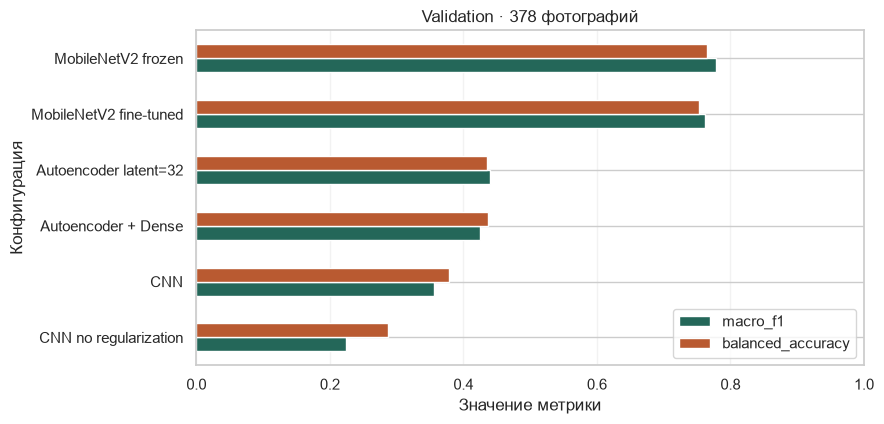

In [12]:
val_table=pd.DataFrame(results).T.sort_values("macro_f1",ascending=False); display(val_table.style.format("{:.3f}").background_gradient(cmap="YlGn",subset=["macro_f1","balanced_accuracy"]))
ax=val_table[["macro_f1","balanced_accuracy"]].sort_values("macro_f1").plot(kind="barh",figsize=(9,4.4),xlim=(0,1),title=f"Validation · {len(val_df)} фотографий",color=["#246759","#b95a31"]); ax.set_xlabel("Значение метрики"); ax.set_ylabel("Конфигурация"); ax.grid(axis="x",alpha=.25); plt.tight_layout(); plt.show()

## 12. Финальная проверка на test

Только после подбора впервые подаём test в модели. Как в исходной ЛР3, проверяем три основные конфигурации. У дополнительных опытов есть только validation-оценки; переносить их на test нельзя.

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,cross_entropy,F1: cardboard,F1: glass,F1: metal,F1: paper,F1: plastic,F1: trash
CNN,0.443,0.387,0.380,0.387,0.362,1.277,0.772,0.172,0.233,0.466,0.529,0.000
MobileNetV2 frozen,0.807,0.760,0.794,0.760,0.771,0.573,0.876,0.795,0.762,0.847,0.818,0.529
Autoencoder + Dense,0.533,0.457,0.476,0.457,0.447,1.245,0.731,0.407,0.341,0.641,0.565,0.000


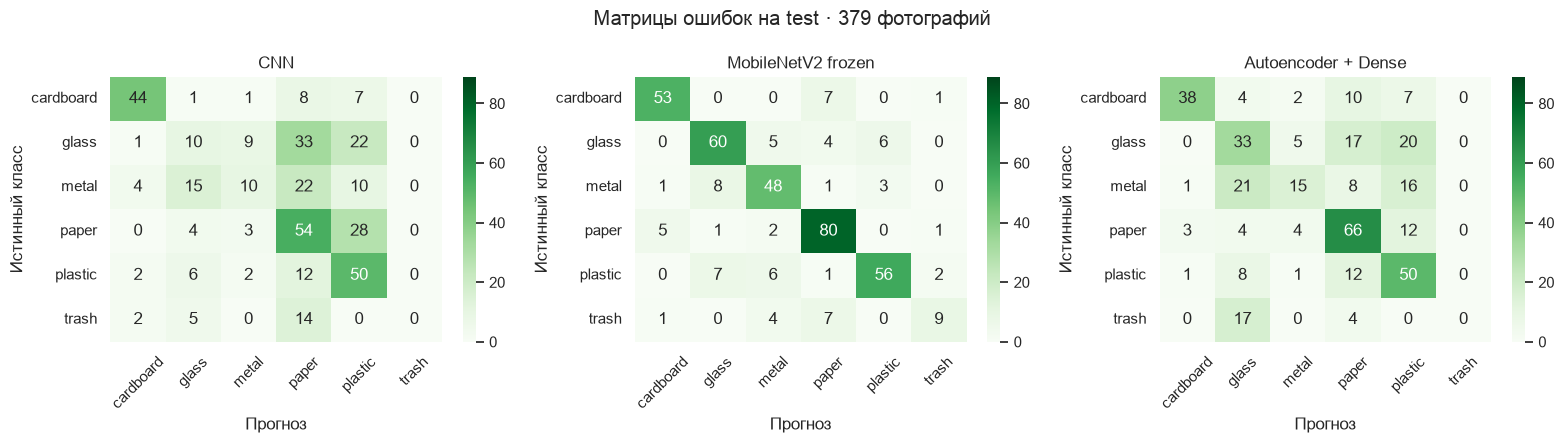

Лучший вариант по validation macro-F1: MobileNetV2 frozen
Отчёт по CNN на test:
              precision    recall  f1-score   support

   cardboard       0.83      0.72      0.77        61
       glass       0.24      0.13      0.17        75
       metal       0.40      0.16      0.23        61
       paper       0.38      0.61      0.47        89
     plastic       0.43      0.69      0.53        72
       trash       0.00      0.00      0.00        21

    accuracy                           0.44       379
   macro avg       0.38      0.39      0.36       379
weighted avg       0.42      0.44      0.41       379



In [13]:
test_ds = make_ds(test_df)
Y_TEST = test_df.label.to_numpy()
Xte = embed(encoder, test_df)
core={"CNN":cnn,"MobileNetV2 frozen":mobile,"Autoencoder + Dense":head}
for name,m in core.items(): test_probs[name]=m.predict(Xte if name=="Autoencoder + Dense" else test_ds,verbose=0)
test_table=pd.DataFrame({n:score(Y_TEST,p) for n,p in test_probs.items()}).T
display(test_table.style.format("{:.3f}").background_gradient(cmap="YlGn",subset=["macro_f1","balanced_accuracy"]))
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
for ax,(name,probs) in zip(axes,test_probs.items()):
    cm=confusion_matrix(Y_TEST,probs.argmax(axis=1),labels=np.arange(NUM_CLASSES)); assert cm.sum() == len(test_df); sns.heatmap(cm,annot=True,fmt="d",cmap="Greens",vmin=0,vmax=int(np.bincount(Y_TEST).max()),xticklabels=class_names,yticklabels=class_names,ax=ax)
    ax.set_title(name); ax.set_xlabel("Прогноз"); ax.set_ylabel("Истинный класс"); ax.tick_params(axis="x",rotation=45); ax.tick_params(axis="y",rotation=0)
plt.suptitle(f"Матрицы ошибок на test · {len(test_df)} фотографий"); plt.tight_layout(); plt.show()
best_val=val_table.index[0]; print("Лучший вариант по validation macro-F1:",best_val)
print("Отчёт по CNN на test:"); print(classification_report(Y_TEST,test_probs["CNN"].argmax(axis=1),target_names=class_names,zero_division=0))

## 13. Итоговый вывод по лабораторной работе
Заключение формируется по измеренным метрикам ниже, а не заранее заданным ожиданиям.

In [14]:
best_val = val_table.index[0]
best_test = test_table.macro_f1.idxmax()
test_f1 = test_table.loc[best_test, "macro_f1"]
test_acc = test_table.loc[best_test, "accuracy"]
val_f1 = val_table.loc[best_val, "macro_f1"]
summary = (
    f"На **test** из {len(test_df)} фото лучший macro-F1 среди основных моделей у **{best_test}**: "
    f"**{test_f1:.3f}**, accuracy **{test_acc:.1%}**. "
    f"На **validation** среди всех конфигураций лидирует **{best_val}**: macro-F1 **{val_f1:.3f}**."
)
lines = [
    "### Выводы по выполненному запуску", "",
    summary, "",
    f"- После очистки **{len(df)}** фото; train / validation / test: **{len(train_df)} / {len(val_df)} / {len(test_df)}**.",
    f"- Macro-F1 собственной CNN на test — **{test_table.loc['CNN', 'macro_f1']:.3f}**, "
    f"автоэнкодера и Dense — **{test_table.loc['Autoencoder + Dense', 'macro_f1']:.3f}**. "
    "Сравнение относится к одному разбиению и заданным лимитам эпох. "
    "Готовые признаки ImageNet могут помочь, но опыт не изолирует эффект предобучения.",
    "- Автоэнкодер учится восстанавливать пиксели, а не различать классы. "
    "Хорошее восстановление не гарантирует высокий F1.",
    "- У дополнительных опытов нет test-оценок. Класс trash встречается заметно реже остальных: "
    "важны macro-F1 и F1 отдельных классов, а не только общая accuracy.",
]
display(Markdown(chr(10).join(lines)))

### Выводы по выполненному запуску

На **test** из 379 фото лучший macro-F1 среди основных моделей у **MobileNetV2 frozen**: **0.771**, accuracy **80.7%**. На **validation** среди всех конфигураций лидирует **MobileNetV2 frozen**: macro-F1 **0.778**.

- После очистки **2521** фото; train / validation / test: **1764 / 378 / 379**.
- Macro-F1 собственной CNN на test — **0.362**, автоэнкодера и Dense — **0.447**. Сравнение относится к одному разбиению и короткому бюджету обучения. Готовые признаки ImageNet могут помочь, но опыт не изолирует эффект предобучения.
- Автоэнкодер учится восстанавливать пиксели, а не различать классы. Хорошее восстановление не гарантирует высокий F1.
- У дополнительных опытов нет test-оценок. Класс trash встречается заметно реже остальных: важны macro-F1 и F1 отдельных классов, а не только общая accuracy.